# Plotting


In this notebook we plot the output from Code 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import plot_utils as pltutils

## Synchrotron SED

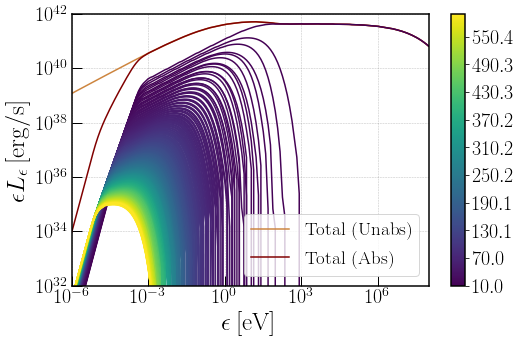

In [20]:
# Load the output of the jet synchrotron SED
synsed_output = np.loadtxt('./../Code/SEDsyn_jet.dat')
synsed_ord = np.loadtxt('./../Code/SEDsyn_cuts_ord.dat')

# Define quantities
nu  = synsed_output[:,0]
tot_un = synsed_output[:,3]
tot_abs = synsed_output[:,4]

# Init plot
fig, ax= plt.subplots(1,1, figsize=(8,5))
colors = pltutils.iar_aut

ax.loglog(nu,tot_un, label='Total (Unabs)', color=colors[0])
ax.loglog(nu,tot_abs, label='Total (Abs)', color=colors[1])


nu = synsed_ord[:,0]
zec = synsed_ord[:,2]
nu = np.reshape(nu,(512,150))
zec = np.reshape(zec,(512,150))
colormap, sm = pltutils.color_from_cmap('viridis',len(nu), vmin=10, vmax=600)
for i in range(len(nu)):
    ax.loglog(nu[i],zec[i], color=colormap[i])

plt.colorbar(sm)
# Set limits#
ax.set_ylim([1e32,1e42])
ax.set_xlim([1e-6,1e8])

# Legends and labels
plt.legend(loc='lower right', fontsize=19)
ax.set_xlabel('$\\epsilon \: [\\rm eV]$')
ax.set_ylabel('$\\epsilon L_{\\epsilon} \: [\\rm erg/s]$')

# Set the style of the plot
pltutils.luc_std_plot(ax)

plt.show()